# Étape 1 — Explorer, fusionner et préparer les données (corrigé)

**Contexte.** Agritech Answers veut une application qui (1) **prédit** le rendement d'une culture à partir des
conditions et (2) **recommande** une culture en simulant toutes les cultures possibles. Deux jeux de données sont
fournis :

| Jeu | Contenu annoncé | Ce qu'on vérifie ici |
|---|---|---|
| *Agriculture Crop Yield* | rendement selon la culture, la région, le sol, la météo, l'engrais, l'irrigation | Est-il réaliste ? Quelles variables comptent ? (ACP demandée) |
| *Crop Yield Prediction* | rendements FAO par pays, culture et année ; pluie, température, pesticides | Peut-on le fusionner proprement ? Avec l'autre jeu ? |

**Ce que produit ce notebook :** le fichier `data/processed/dataset_consolide.csv`, source de vérité des étapes
suivantes, et le résumé écrit des choix (section 6). Le même code tourne sans notebook : `uv run agrireco prepare`.

## 1. Environnement et données

In [1]:
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from agrireco import io, prepare, synthetic, viz
from agrireco.viz import CROPS_FR, fr, pct

viz.apply_style()
pd.set_option("display.precision", 3)
print("Python", sys.version.split()[0])
for lib in ["pandas", "numpy", "scikit-learn", "matplotlib", "mlflow"]:
    print(f"{lib:<13} {version(lib)}")

Python 3.12.15
pandas        3.1.0
numpy         2.5.4
scikit-learn  1.9.1
matplotlib    3.11.2
mlflow        3.17.2


`io.download()` télécharge la pièce jointe de la mission (un zip qui contient deux zips), **vérifie son empreinte
SHA-256** puis extrait les fichiers dans `data/raw/`. Si le fichier publié change un jour, le code s'arrête au lieu
de produire en silence d'autres chiffres que ceux de ce corrigé.

In [2]:
agri_dir, fao_dir = io.download()
for d in (agri_dir, fao_dir):
    print(d.name, "→", sorted(p.name for p in d.iterdir()))

agriculture_crop_yield → ['crop_yield.csv']
crop_yield_prediction → ['pesticides.csv', 'rainfall.csv', 'temp.csv', 'yield.csv', 'yield_df.csv']


## 2. Le jeu « Agriculture Crop Yield »

In [3]:
agri = pd.read_csv(agri_dir / "crop_yield.csv")
print(agri.shape)
print("valeurs manquantes :", int(agri.isna().sum().sum()), "| lignes en double :", int(agri.duplicated().sum()))
agri.head()

(1000000, 10)


valeurs manquantes : 0 | lignes en double : 0


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077,27.677,False,True,Cloudy,122,6.556
1,South,Clay,Rice,992.673,18.026,True,True,Rainy,140,8.527
2,North,Loam,Barley,147.998,29.794,False,False,Sunny,106,1.127
3,North,Sandy,Soybean,986.866,16.644,False,True,Rainy,146,6.518
4,South,Silt,Wheat,730.379,31.621,True,True,Cloudy,110,7.248


In [4]:
agri.describe().T

,count,mean,std,min,25%,50%,75%,max
Rainfall_mm,1000000.0,549.982,259.851,100.001,324.891,550.124,774.739,999.998
Temperature_Celsius,1000000.0,27.505,7.221,15.000,21.255,27.507,33.753,40.000
Days_to_Harvest,1000000.0,104.495,25.953,60.000,82.000,104.000,127.000,149.000
Yield_tons_per_hectare,1000000.0,4.649,1.697,-1.148,3.418,4.652,5.879,9.963


In [5]:
for col in ["Region", "Soil_Type", "Crop", "Weather_Condition", "Fertilizer_Used", "Irrigation_Used"]:
    print(f"{col:<18}", agri[col].value_counts(normalize=True).round(3).to_dict())

Region             {'North': 0.25, 'West': 0.25, 'South': 0.25, 'East': 0.25}
Soil_Type          {'Sandy': 0.167, 'Loam': 0.167, 'Chalky': 0.167, 'Silt': 0.167, 'Clay': 0.166, 'Peaty': 0.166}
Crop               {'Maize': 0.167, 'Rice': 0.167, 'Barley': 0.167, 'Wheat': 0.167, 'Cotton': 0.167, 'Soybean': 0.166}
Weather_Condition  {'Sunny': 0.334, 'Rainy': 0.334, 'Cloudy': 0.333}
Fertilizer_Used    {False: 0.5, True: 0.5}
Irrigation_Used    {False: 0.501, True: 0.499}


**Premier signal d'alerte.** Un million de lignes, aucune valeur manquante, aucun doublon, et toutes les catégories
à parts presque parfaitement égales (6 cultures à environ 1/6 chacune, engrais et irrigation à 50 %). Des données
agricoles réelles ne ressemblent jamais à ça : on soupçonne un jeu **simulé**. On le vérifie au lieu de le supposer.

In [6]:
n_neg = int((agri["Yield_tons_per_hectare"] < 0).sum())
print("rendements négatifs (physiquement impossibles) :", n_neg)
agri.groupby("Crop")["Yield_tons_per_hectare"].agg(["mean", "std", "count"])

rendements négatifs (physiquement impossibles) : 231


,mean,std,count
Crop,,,
Barley,4.647,1.698,166777
Cotton,4.651,1.695,166585
Maize,4.641,1.696,166824
Rice,4.651,1.698,166792
Soybean,4.654,1.697,166349
Wheat,4.653,1.695,166673


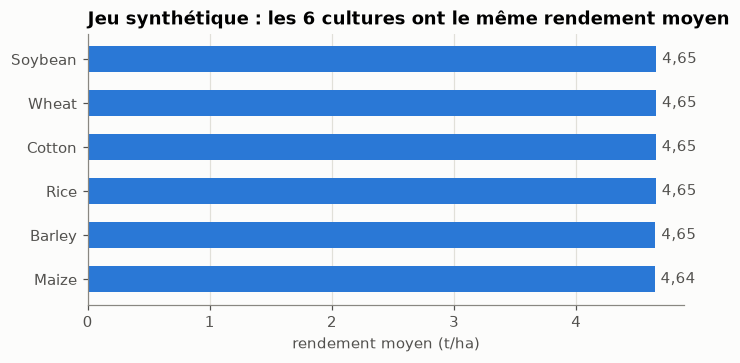

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
means = agri.groupby("Crop")["Yield_tons_per_hectare"].mean().sort_values()
ax.barh(means.index, means.values, color=viz.BLUE, height=0.6)
for i, v in enumerate(means.values):
    ax.text(v + 0.05, i, fr(v), va="center", color=viz.TEXT_2)
ax.set_xlabel("rendement moyen (t/ha)")
ax.set_title("Jeu synthétique : les 6 cultures ont le même rendement moyen")
ax.grid(axis="y", visible=False)
viz.save(fig, "synthetique_rendement_par_culture")
plt.show()

Blé, riz, coton ou soja : **le même rendement moyen, à un centième près**. Dans la réalité, une tonne de coton par
hectare et une tonne de riz n'ont rien à voir. Le jeu contient aussi des rendements négatifs, impossibles.
Une régression linéaire confirme ce qu'on soupçonne :

In [8]:
coef, r2 = synthetic.raw_effects(agri)
print("R² de la régression linéaire :", fr(r2, 3))
effets = coef.drop("constante").sort_values(key=abs, ascending=False)
effets.map(lambda v: f"{v:+.4f}").to_frame("effet brut (t/ha par unité)")

R² de la régression linéaire : 0,913


,effet brut (t/ha par unité)
Fertilizer_Used,+1.5004
Irrigation_Used,+1.1996
Temperature_Celsius,+0.0199
Rainfall_mm,+0.0050
Soil_Type_Clay,+0.0037
Crop_Maize,-0.0031
Crop_Wheat,-0.0028
Soil_Type_Sandy,+0.0017
Weather_Condition_Rainy,+0.0014
Region_West,-0.0012


Une simple droite explique **91 % des variations** du rendement, avec quatre variables seulement :

- engrais utilisé : **+1,50 t/ha** ; irrigation : **+1,20 t/ha** ;
- pluie : +0,005 t/ha par mm (soit +0,5 t/ha pour 100 mm de plus) ; température : +0,02 t/ha par °C ;
- culture, sol, région, météo, durée avant récolte : **effet nul** (coefficients de l'ordre du millième).

⚠️ Ces coefficients ont des **unités différentes** (par mm, par °C, oui/non) : on ne peut pas les comparer tels
quels. On les ramène à la variation typique de chaque variable (un écart-type) :

In [9]:
synthetic.effects_per_sd(agri, coef).map(lambda v: f"{v:.2f}").to_frame("effet d'un écart-type (t/ha)")

,effet d'un écart-type (t/ha)
Rainfall_mm,1.30
Fertilizer_Used,0.75
Irrigation_Used,0.60
Temperature_Celsius,0.14
Days_to_Harvest,0.00


Rapportée à sa variation typique, **la pluie pèse le plus** (1,30 t/ha par écart-type ; de 100 à 1 000 mm, elle
fait varier le rendement d'environ 4,5 t/ha), devant l'engrais (0,75) et l'irrigation (0,60). Pour une variable
oui/non, l'écart-type dépend de la proportion (ici 50/50) : on lit aussi l'effet brut, +1,50 et +1,20 t/ha.

Ce sont les **paramètres de la simulation** qui a fabriqué ce jeu, pas une connaissance agronomique. On peut les
citer comme « ce que dit ce jeu », jamais comme « ce que fait l'irrigation dans la vraie vie ».

### ACP (demandée par l'énoncé)

L'ACP cherche des **directions** qui résument plusieurs variables corrélées. On l'applique aux 5 variables
explicatives numériques ou binaires, **toutes standardisées** (sinon les variables 0/1, de variance 0,25, pèseraient
quatre fois moins que les autres). Le rendement n'entre pas dans l'ACP : on regardera ensuite s'il est lié aux axes.

In [10]:
res = synthetic.pca(agri)
eig = pd.DataFrame({"valeur propre": res["eigenvalues"], "part de variance": res["explained"]},
                   index=[f"CP{k + 1}" for k in range(len(res["eigenvalues"]))])
eig

,valeur propre,part de variance
CP1,1.003,0.201
CP2,1.003,0.201
CP3,1.001,0.200
CP4,0.997,0.199
CP5,0.997,0.199


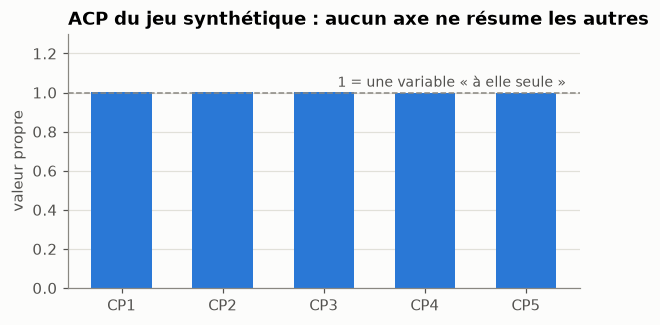

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(eig.index, eig["valeur propre"], color=viz.BLUE, width=0.6)
ax.axhline(1, color=viz.MUTED, lw=1, ls="--")
ax.text(4.4, 1.03, "1 = une variable « à elle seule »", ha="right", color=viz.TEXT_2, fontsize=9)
ax.set_ylim(0, 1.3)
ax.set_ylabel("valeur propre")
ax.set_title("ACP du jeu synthétique : aucun axe ne résume les autres")
ax.grid(axis="x", visible=False)
viz.save(fig, "synthetique_acp_eboulis")
plt.show()

**Lecture.** Les 5 valeurs propres valent toutes **environ 1** (de 0,997 à 1,003) : chaque composante porte 20 % de
l'information, exactement ce que porterait une variable seule. Les variables sont **indépendantes** : il n'y a
aucune structure à résumer et **aucune réduction de dimension possible**.

⚠️ Quand les valeurs propres sont égales, les axes sont **arbitraires** : n'importe quelle rotation conviendrait
aussi bien. On ne lit donc ni les axes, ni le cercle des corrélations, ni la corrélation « CP1 – rendement » : ce
serait interpréter du bruit.

**Ce que l'ACP ne fait pas :** dire quelles variables *prédisent* le rendement. Elle ne regarde pas la cible. Les
variables clés de ce jeu viennent de la régression ci-dessus (pluie, engrais, irrigation). C'est la principale
leçon de cette partie : une ACP « vide » n'est pas un échec, c'est une information sur les données.

## 3. Le jeu « Crop Yield Prediction » (FAO et Banque mondiale)

In [12]:
yield_df = pd.read_csv(fao_dir / "yield_df.csv", index_col=0)
key = ["Area", "Item", "Year"]
print("lignes :", len(yield_df), "| clés (pays, culture, année) distinctes :", len(yield_df.drop_duplicates(key)))
yield_df.head()

lignes : 28242 | clés (pays, culture, année) distinctes : 13130


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [13]:
dups = yield_df[yield_df.duplicated(key, keep=False)].sort_values(key)
print("lignes impliquées dans un doublon :", len(dups))
print(dups["Area"].value_counts().head(5).to_dict())
dups.head(6)

lignes impliquées dans un doublon : 18949
{'India': 4048, 'Brazil': 2277, 'Mexico': 1472, 'Pakistan': 1449, 'Australia': 966}


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
377,Argentina,Cassava,1990,100000,591.0,26156.0,17.46
378,Argentina,Cassava,1990,100000,591.0,26156.0,17.67
393,Argentina,Cassava,1991,100000,591.0,26156.0,17.64
394,Argentina,Cassava,1991,100000,591.0,26156.0,17.86
409,Argentina,Cassava,1992,100000,591.0,26156.0,17.09
410,Argentina,Cassava,1992,100000,591.0,26156.0,17.51


**Piège n° 1 : la table « prête à l'emploi » est faussée.** `yield_df.csv` compte 28 242 lignes, mais seulement
**13 130 combinaisons (pays, culture, année)**. Pour un même maïs indien de 2005, on trouve plusieurs lignes qui ne
diffèrent que par la température. La raison : `temp.csv` contient **plusieurs stations par pays** (l'Inde, le
Brésil, le Mexique…), et la jointure les a multipliées. Un modèle entraîné dessus verrait l'Inde des dizaines de
fois, et un découpage aléatoire mettrait des copies de la même ligne en entraînement et en test.

On reconstruit donc la table depuis les **fichiers bruts**.

In [14]:
y_raw, rain_raw, pest_raw, temp_raw = prepare.load_fao_raw(fao_dir)
for name, df in [("yield", y_raw), ("rainfall", rain_raw), ("pesticides", pest_raw), ("temp", temp_raw)]:
    print(f"{name:<11} {df.shape}  colonnes : {list(df.columns)[:6]}")

yield       (56717, 12)  colonnes : ['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element']
rainfall    (6727, 3)  colonnes : [' Area', 'Year', 'average_rain_fall_mm_per_year']
pesticides  (4349, 7)  colonnes : ['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit']
temp        (71311, 3)  colonnes : ['year', 'country', 'avg_temp']


In [15]:
rain_raw.columns = rain_raw.columns.str.strip()  # la colonne « Area » s'appelle « ␣Area » dans le fichier
bad = pd.to_numeric(rain_raw["average_rain_fall_mm_per_year"], errors="coerce").isna()
print("valeurs de pluie non numériques :", int(bad.sum()), "→", list(rain_raw.loc[bad, "average_rain_fall_mm_per_year"].unique()))
print("unités des rendements :", list(y_raw["Unit"].unique()), "| des pesticides :", list(pest_raw["Unit"].unique()))

valeurs de pluie non numériques : 780 → [nan, '..']
unités des rendements : ['hg/ha'] | des pesticides : ['tonnes of active ingredients']


**Piège n° 2 : les noms de pays.** Chaque fichier vient d'une source différente : `United States of America` (FAO)
s'écrit `United States` dans les fichiers de pluie et de température, `Russian Federation` s'écrit `Russia`,
`Viet Nam` s'écrit `Vietnam`… Une jointure fait correspondre des chaînes de caractères exactes : ces pays
**disparaissent en silence**. On les retrouve avec une *anti-jointure* (les noms présents d'un côté et absents de
l'autre) :

In [16]:
fao_names = set(y_raw["Area"])
temp_names = set(temp_raw["country"])
print(sorted(temp_names - fao_names))

['Bolivia', 'Bosnia And Herzegovina', 'Congo (Democratic Republic Of The)', 'Czech Republic', "Côte D'Ivoire", 'Guinea Bissau', 'Hong Kong', 'Iran', 'Laos', 'Macedonia', 'Moldova', 'Russia', 'South Korea', 'Syria', 'Taiwan', 'Tanzania', 'United States', 'Venezuela', 'Vietnam']


On en tire une table de correspondance explicite (`prepare.COUNTRY_ALIASES`, testée), plus un cas particulier :
« China » est dans le fichier FAO un **agrégat** (continent + Taïwan + Hong Kong + Macao) qui doublonnerait
« China, mainland ». La pluie et la température « China » sont rattachées à la Chine continentale et l'agrégat est
retiré. La température est **moyennée** sur les stations d'un même pays et d'une même année.

In [17]:
fao, journal = prepare.build_fao_table(y_raw, rain_raw, pest_raw, temp_raw)
journal

,etape,lignes
0,rendements FAO (toutes années),56717
1,sans l'agrégat « China »,56269
2,après jointure pluie,29042
3,après jointure pesticides,21984
4,après jointure température,15794


In [18]:
print(f"{len(fao)} lignes, {fao['country'].nunique()} pays, {fao['crop'].nunique()} cultures, "
      f"{fao['year'].min()}-{fao['year'].max()}")
recovered = sorted(set(fao["country"]) - set(yield_df["Area"]))
print(len(recovered), "pays récupérés par l'harmonisation :", recovered)
prepare.check_unique_key(fao)  # lève une erreur s'il reste un doublon

15794 lignes, 119 pays, 10 cultures, 1990-2013
18 pays récupérés par l'harmonisation : ['Bolivia (Plurinational State of)', 'China, mainland', 'Congo', 'Czechia', "Côte d'Ivoire", 'Guinea-Bissau', 'Iran (Islamic Republic of)', "Lao People's Democratic Republic", 'Republic of Korea', 'Republic of Moldova', 'Russian Federation', 'Slovakia', 'Syrian Arab Republic', 'The former Yugoslav Republic of Macedonia', 'United Republic of Tanzania', 'United States of America', 'Venezuela (Bolivarian Republic of)', 'Viet Nam']


La table reconstruite compte **15 794 lignes, 119 pays, 10 cultures, de 1990 à 2013**, avec une clé unique : 2 664
lignes de plus que les 13 130 clés de `yield_df.csv`, grâce à **18 pays récupérés**, dont les États-Unis, la Russie
et la Chine continentale, trois des plus gros producteurs mondiaux. Le journal montre où partent les lignes : surtout
aux jointures avec les pesticides et la température, qui ne couvrent pas tous les pays ni toutes les années (on ne
garde que 1990-2013, la période commune).

## 4. Exploration de la table FAO consolidée

In [19]:
fao.describe().T

,count,mean,std,min,25%,50%,75%,max
year,15794.0,2001.631,7.023,1990.000,1995.000,2001.000,2008.000,2.013e+03
yield_t_ha,15794.0,6.931,7.706,0.005,1.806,3.936,9.375,5.014e+01
rainfall_mm,15794.0,1149.226,715.566,51.000,619.000,1083.000,1646.000,3.240e+03
pesticides_t,15794.0,32882.405,153718.618,0.040,207.000,2414.510,14216.000,1.806e+06
avg_temp,15794.0,19.552,6.856,1.300,14.620,20.513,25.910,3.042e+01


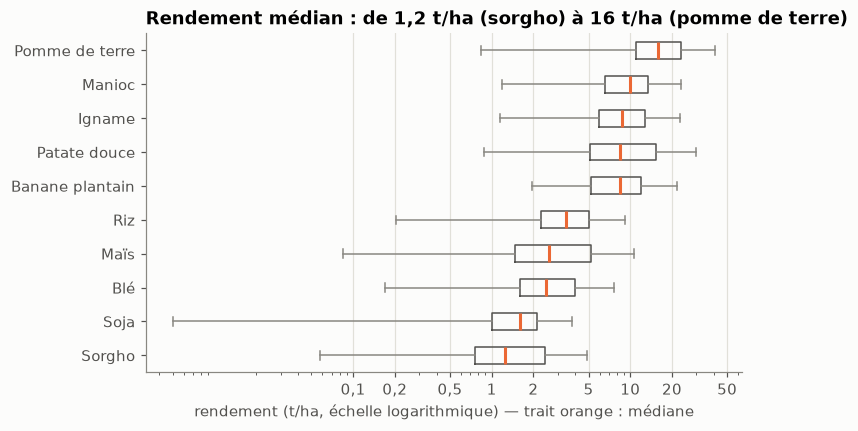

crop,Sorgho,Soja,Blé,Maïs,Riz,Banane plantain,Patate douce,Igname,Manioc,Pomme de terre
médiane (t/ha),1.2,1.6,2.5,2.6,3.5,8.4,8.4,8.7,10.0,16.0


In [20]:
per_crop = fao.groupby("crop")["yield_t_ha"].median().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
data = [fao.loc[fao["crop"] == c, "yield_t_ha"] for c in per_crop.index]
ax.boxplot(data, orientation="horizontal", widths=0.5, showfliers=False,
           medianprops={"color": viz.ORANGE, "lw": 2}, boxprops={"color": viz.TEXT_2},
           whiskerprops={"color": viz.MUTED}, capprops={"color": viz.MUTED})
ax.set_yticks(range(1, len(per_crop) + 1), [CROPS_FR[c] for c in per_crop.index])
ax.set_xscale("log")
ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50], ["0,1", "0,2", "0,5", "1", "2", "5", "10", "20", "50"])
ax.set_xlabel("rendement (t/ha, échelle logarithmique) — trait orange : médiane")
ax.set_title("Rendement médian : de 1,2 t/ha (sorgho) à 16 t/ha (pomme de terre)")
ax.grid(axis="y", visible=False)
viz.save(fig, "fao_rendement_par_culture")
plt.show()
per_crop.round(1).rename(index=CROPS_FR).to_frame("médiane (t/ha)").T

**Piège n° 3 : les tonnes par hectare ne se comparent pas d'une culture à l'autre.** La pomme de terre (médiane
16,0 t/ha) et le manioc (10,0 t/ha) sont lourds et gorgés d'eau ; le sorgho (1,2 t/ha) et le soja (1,6 t/ha) sont des
grains secs. Classer les cultures par t/ha reviendrait à recommander presque toujours la pomme de terre. C'est pour
cela que la recommandation utilisera un **rendement relatif** (étape 2). Autre conséquence : les médianes vont du
simple au treizuple (1,2 à 16,0 t/ha), d'où une modélisation du **logarithme** du rendement.
(Les moustaches montrent l'étendue des valeurs hors extrêmes : certains pays-années descendent sous 0,1 t/ha.)

In [21]:
profil = fao.groupby("country").agg(
    valeurs_de_pluie=("rainfall_mm", "nunique"),
    ecart_type_temperature=("avg_temp", "std"),
)
print("pays dont la pluie ne change jamais :", int((profil["valeurs_de_pluie"] == 1).sum()), "sur", len(profil))
between = fao.groupby("country")["avg_temp"].mean().std()
within = profil["ecart_type_temperature"].mean()
print(f"température : écart-type entre pays {fr(between)} °C, au sein d'un pays {fr(within)} °C")

pays dont la pluie ne change jamais : 119 sur 119
température : écart-type entre pays 7,46 °C, au sein d'un pays 0,46 °C


**Piège n° 4 : ce sont des moyennes nationales, pas des mesures à la parcelle.**

- La pluie est **une seule valeur par pays** pour toute la période (119 pays sur 119) : c'est la pluie « normale »
  du pays, elle ne dit rien d'une année sèche ou humide. Elle sert d'identifiant du pays.
- La température varie beaucoup plus d'un pays à l'autre qu'au sein d'un pays.
- Les pesticides sont des **tonnes totales par pays**, pas des kg/ha : la Chine en utilise des centaines de fois
  plus que la Belgique parce qu'elle est immense, pas parce que chaque champ en reçoit plus.

Le modèle ne pourra donc prédire que le **rendement moyen national** d'une culture dans un pays aux conditions
données, pas celui d'une parcelle. On le dira dans l'application.

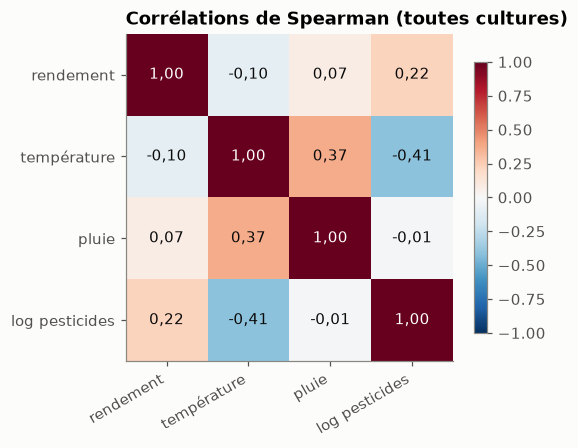

In [22]:
num = prepare.add_model_features(fao)[["yield_t_ha", "avg_temp", "rainfall_mm", "log10_pesticides_t"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = ["rendement", "température", "pluie", "log pesticides"]
ax.set_xticks(range(4), labels, rotation=30, ha="right")
ax.set_yticks(range(4), labels)
for i in range(4):
    for j in range(4):
        ax.text(j, i, fr(corr.iloc[i, j]), ha="center", va="center", color=viz.TEXT if abs(corr.iloc[i, j]) < 0.6 else "white")
ax.grid(False)
ax.set_title("Corrélations de Spearman (toutes cultures)")
fig.colorbar(im, ax=ax, shrink=0.8)
viz.save(fig, "fao_correlations")
plt.show()

Toutes cultures confondues, aucune variable n'est fortement liée au rendement (|ρ| ≤ 0,22) : la culture écrase tout.
La température est liée à la pluie (ρ = 0,37) et inversement aux pesticides (ρ = −0,41) : les pays chauds utilisent
en moyenne moins de pesticides. Ces liens entre variables expliqueront pourquoi leur « importance » sera difficile à
répartir (étape 2). Spearman plutôt que Pearson : les distributions sont très asymétriques (pesticides).

## 5. Peut-on fusionner les deux jeux ?

L'énoncé propose de fusionner les deux jeux sur une clé commune, par exemple le pays et l'année. Or le jeu
synthétique **n'a ni pays ni année** : il n'a que quatre « régions » (North, South, East, West). La seule colonne
commune est la **culture**, et seules 4 cultures existent des deux côtés (maïs, riz, blé, soja). On essaie quand
même, en agrégeant le jeu synthétique par culture :

In [23]:
joined = prepare.join_on_crop(fao, agri)
print(len(joined), "lignes sur", len(fao), "(cultures communes :", sorted(joined["crop"].unique()), ")")
joined.groupby("crop")[["agri_fertilizer_rate", "agri_irrigation_rate", "agri_mean_yield_t_ha"]].first()

7942 lignes sur 15794 (cultures communes : ['Maize', 'Rice, paddy', 'Soybeans', 'Wheat'] )


,agri_fertilizer_rate,agri_irrigation_rate,agri_mean_yield_t_ha
crop,,,
Maize,0.498,0.500,4.641
"Rice, paddy",0.500,0.496,4.651
Soybeans,0.500,0.501,4.654
Wheat,0.501,0.501,4.653


**Conclusion : la fusion est dégénérée.** Les colonnes ajoutées valent partout la même chose (50 % d'engrais, 50 %
d'irrigation, 4,65 t/ha), à la deuxième décimale près : elles n'apportent **aucune information**, et la jointure
fait perdre la moitié des lignes (les 6 cultures FAO absentes du jeu synthétique). Joindre sans vraie clé commune,
ce serait fabriquer de l'information.

**Choix retenu :**

1. La « vraie » fusion du projet est celle des 4 fichiers FAO / Banque mondiale (rendement, pluie, pesticides,
   température), avec noms de pays harmonisés : c'est le jeu consolidé qui alimente le modèle.
2. Le jeu synthétique sert à l'ACP demandée et à décrire l'effet de l'engrais et de l'irrigation **dans la
   simulation**. Il ne peut pas « valider » le jeu FAO : il dit « l'eau et les intrants comptent, la culture non »,
   le jeu FAO dit « la culture domine ». Leur désaccord montre que le jeu synthétique ne décrit pas la réalité
   agronomique.

## 6. Fichier consolidé et résumé des choix

In [24]:
out = io.PROJECT_DIR / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)
fao.to_csv(out / "dataset_consolide.csv", index=False)
journal.to_csv(out / "journal_fusion.csv", index=False)
print("colonnes :", list(fao.columns))
print("écrit :", (out / "dataset_consolide.csv").relative_to(io.PROJECT_DIR), f"({len(fao)} lignes)")

colonnes : ['country', 'crop', 'year', 'yield_t_ha', 'rainfall_mm', 'pesticides_t', 'avg_temp']
écrit : data/processed/dataset_consolide.csv (15794 lignes)


**Résumé pour le rapport métier**

| Décision | Choix | Pourquoi |
|---|---|---|
| Source du modèle | Table FAO reconstruite depuis les fichiers bruts | `yield_df.csv` contient 15 112 lignes en double |
| Noms de pays | Table de correspondance (18 pays récupérés) | Sinon les États-Unis, la Russie, la Chine… disparaissent |
| Température | Moyenne des stations d'un pays et d'une année | Une ligne par (pays, culture, année) |
| Pluie non renseignée (`..`) | Ligne retirée, pas d'imputation | Ne pas inventer de valeur |
| Unité | Rendement en t/ha | Parlant pour un agriculteur |
| Jeu synthétique | Pas fusionné : ACP et effets décrits à part | Aucune clé commune réelle ; colonnes constantes après jointure par culture |
| Colonnes du CSV | pays, culture, année, rendement, pluie, pesticides, température | Une colonne par information, sans redondance |

**Variables clés.** Dans le jeu FAO, la **culture** détermine l'ordre de grandeur du rendement ; la température et
les pesticides (indicateur de la taille et de l'intensité agricole du pays) viennent ensuite ; la pluie, une valeur
fixe par pays, apporte peu. Dans le jeu synthétique, la pluie (environ 4,5 t/ha d'écart entre 100 et 1 000 mm),
l'engrais (+1,50 t/ha) et l'irrigation (+1,20 t/ha) dominent, mais par construction de la simulation. L'étape 2 mesure ce que chaque variable apporte réellement à la prédiction.